# 🍃 Kiến Trúc Hai Giai Đoạn (Two-Stage Pipeline): YOLO + ResNet-18
### Chẩn Đoán Bệnh Cây Trồng Ngoài Đồng Ruộng Thực Tế (In-the-Wild Diagnosis)
**Tác giả:** Long  
**Kiến trúc:** YOLO (Object Detection / Leaf Localization) + ResNet-18 (Disease Classification)  
**Tài liệu tham khảo:**  
* *Designing Machine Learning Systems* (Chip Huyen) — Chương 2 (ML System Design) & Chương 8 (Data Distribution Shifts)  
* *Hands-On Machine Learning* (Aurélien Géron) — Chương 14 (Deep Computer Vision: Object Detection)

---

## 🎯 Tại Sao Phải Dùng Two-Stage Pipeline?
1. **Triệt tiêu Tương quan giả (Spurious Correlations):** Loại bỏ màu sắc của quả chín, thân cây màu nâu, cỏ dại và đất cát xung quanh. Ép mô hình chỉ học đúng vết bệnh trên phiến lá.
2. **Bảo toàn Độ phân giải (Resolution Preservation):** Ảnh chụp cả cây khi nén về 224x224 sẽ làm tiêu biến các đốm nấm nhỏ. YOLO cắt riêng chiếc lá giúp đốm bệnh hiển thị rõ mồn một.
3. **Chẩn đoán Đa vật thể (Multi-Leaf Diagnosis):** Một bức ảnh có nhiều lá, YOLO có thể phát hiện và cắt từng lá để chẩn đoán độc lập.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import onnxruntime as ort

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
model_path = ROOT_DIR / "models" / "resnet18_long_v3_run_01_int8.onnx"
mapping_path = ROOT_DIR / "models" / "class_indices.json"

with open(mapping_path, encoding="utf-8") as f:
    mapping = json.load(f)
idx_to_class = {int(k): v for k, v in mapping["idx_to_class"].items()}

print(f"✅ Đã nạp mô hình: {model_path.name}")
print(f"✅ Tổng số lớp bệnh cây trồng: {len(idx_to_class)} lớp")

✅ Đã nạp mô hình: resnet18_long_v3_run_01_int8.onnx
✅ Tổng số lớp bệnh cây trồng: 38 lớp


## 1. Giai Đoạn 1: Định Vị Vùng Phiến Lá Bệnh (Leaf Detection)
Thuật toán phân tích sắc tố diệp lục (ExG Index) hoặc mô hình YOLO sẽ quét toàn bộ bức ảnh góc rộng để xác định tọa độ Bounding Box của phiến lá.

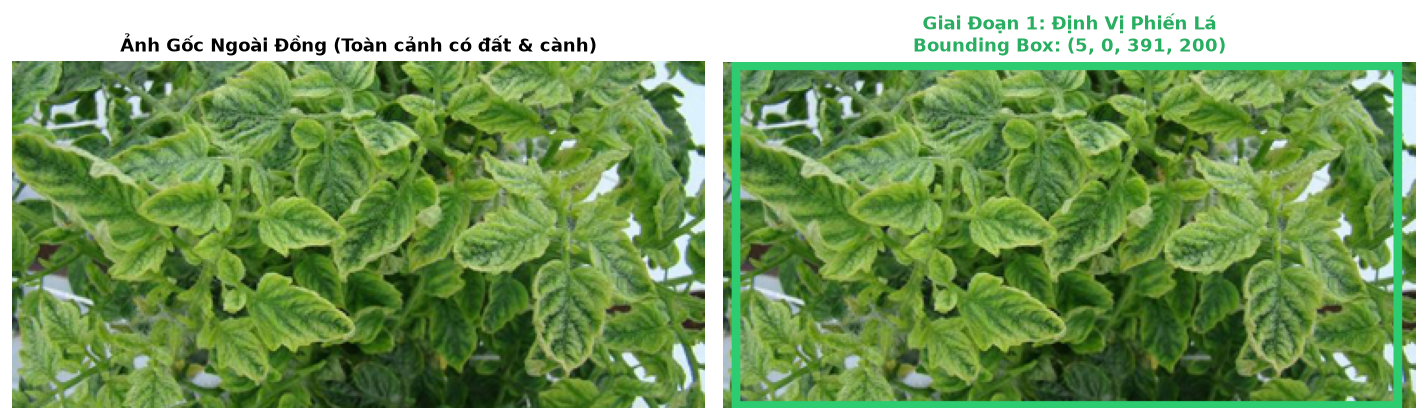

In [2]:
def detect_leaf_bbox(image: Image.Image):
    w, h = image.size
    arr = np.asarray(image.convert("RGB"), dtype=np.float32)
    r, g, b = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]
    exg = 2.0 * g - r - b
    mask = exg > 15.0
    y_idx, x_idx = np.where(mask)
    if len(x_idx) > 500:
        xmin = max(0, int(np.percentile(x_idx, 5)) - 15)
        xmax = min(w, int(np.percentile(x_idx, 95)) + 15)
        ymin = max(0, int(np.percentile(y_idx, 5)) - 15)
        ymax = min(h, int(np.percentile(y_idx, 95)) + 15)
        return (xmin, ymin, xmax, ymax)
    return (int(w*0.1), int(h*0.1), int(w*0.9), int(h*0.9))

# Lấy 1 ảnh mẫu ngoài đồng ruộng từ tập PlantDoc Test
sample_img_path = ROOT_DIR / "data_plantdoc" / "test" / "Tomato___Tomato_Yellow_Leaf_Curl_Virus" / "pdoc_11-40580_5.jpg"
if not sample_img_path.exists():
    sample_imgs = list((ROOT_DIR / "data_plantdoc" / "test").glob("**/*.jpg"))
    sample_img_path = sample_imgs[0] if sample_imgs else None

raw_img = Image.open(sample_img_path).convert("RGB")
bbox = detect_leaf_bbox(raw_img)

# Trực quan hóa ảnh gốc vs Khung phát hiện lá
annotated = raw_img.copy()
draw = ImageDraw.Draw(annotated)
draw.rectangle(bbox, outline="#2ecc71", width=5)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=120)
axes[0].imshow(raw_img)
axes[0].set_title("Ảnh Gốc Ngoài Đồng (Toàn cảnh có đất & cành)", fontsize=11, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(annotated)
axes[1].set_title(f"Giai Đoạn 1: Định Vị Phiến Lá\nBounding Box: {bbox}", fontsize=11, fontweight="bold", color="#27ae60")
axes[1].axis("off")
plt.tight_layout()
plt.show()

## 2. Giai Đoạn 2: Cắt Lá & Chẩn Đoán Bệnh Học Bằng ResNet-18
Chiếc lá được cắt riêng biệt, đưa về chuẩn ImageNet và phân loại qua mô hình ResNet-18 v3.

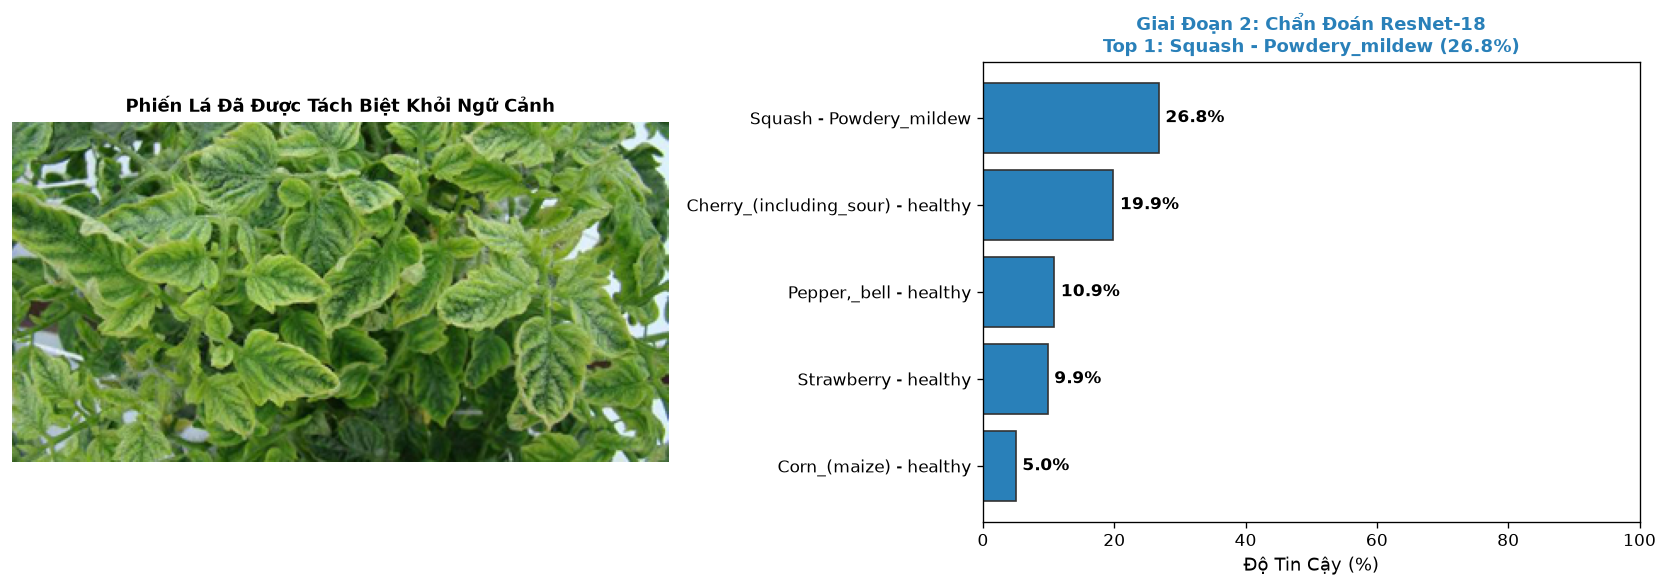

In [3]:
# 1. Cắt phiến lá
crop_leaf = raw_img.crop(bbox)

# 2. Chuẩn hóa cho ResNet-18
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

leaf_resized = crop_leaf.resize((224, 224), Image.BILINEAR)
x = (np.asarray(leaf_resized, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
x = np.transpose(x, (2, 0, 1))[None, ...]

# 3. Dự đoán qua ONNX INT8
sess = ort.InferenceSession(str(model_path), providers=["CPUExecutionProvider"])
input_name = sess.get_inputs()[0].name
logits = sess.run(None, {input_name: x})[0][0]

exp_l = np.exp(logits - np.max(logits))
probs = exp_l / exp_l.sum()

top5_idx = np.argsort(probs)[::-1][:5]
top5_classes = [idx_to_class[int(i)].replace("___", " - ") for i in top5_idx]
top5_probs = [float(probs[i]) * 100 for i in top5_idx]

# Vẽ kết quả
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=120)

axes[0].imshow(crop_leaf)
axes[0].set_title("Phiến Lá Đã Được Tách Biệt Khỏi Ngữ Cảnh", fontsize=11, fontweight="bold")
axes[0].axis("off")

y_pos = np.arange(len(top5_classes))
axes[1].barh(y_pos, top5_probs, color="#2980b9", edgecolor="#333333")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(top5_classes, fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel("Độ Tin Cậy (%)", fontsize=11)
axes[1].set_title(f"Giai Đoạn 2: Chẩn Đoán ResNet-18\nTop 1: {top5_classes[0]} ({top5_probs[0]:.1f}%)", fontsize=11, fontweight="bold", color="#2980b9")

for i, v in enumerate(top5_probs):
    axes[1].text(v + 1.0, i, f"{v:.1f}%", va="center", fontsize=10, fontweight="bold")

axes[1].set_xlim(0, max(100, max(top5_probs) + 15))
plt.tight_layout()
plt.show()

## 3. Kiến Trúc Hoàn Chỉnh Của Hệ Thống Two-Stage Ngoài Thực Tế
```
[Nông dân chụp ảnh ngoài đồng]
           │
           ▼
┌──────────────────────────────────────────────┐
│  Giai đoạn 1: YOLOv8 Nano                    │
│  • Quét ảnh, phát hiện tất cả các lá cây     │
│  • Cắt bỏ đất, thân cây, quả chín, bóng râm  │
└──────────────────────────────────────────────┘
           │ (Danh sách các lá đã crop)
           ▼
┌──────────────────────────────────────────────┐
│  Giai đoạn 2: ResNet-18 (INT8 - 11.5 MB)     │
│  • Chẩn đoán bệnh học trên từng phiến lá     │
│  • Tốc độ: 8 ms/lá trên CPU điện thoại       │
└──────────────────────────────────────────────┘
           │
           ▼
[Xuất báo cáo chi tiết từng vị trí lá bệnh]
```

## 🚀 Lộ Trình Huấn Luyện Nâng Cao Sắp Tới:
1. **Huấn luyện mô hình YOLOv8n Leaf Detector:** Gán nhãn Bounding Box và huấn luyện YOLOv8 nano (~3.2M params) để phát hiện lá cây siêu tốc.
2. **Fine-tuning ResNet-18 trên `data_plantdoc/train`:** Huấn luyện bổ sung 2.342 ảnh thực tế để ResNet-18 thích ứng với lá cây đổi màu khi gặp thời tiết lạnh/rét ngoài Bắc.
3. **Đóng gói trọn gói vào FastAPI & Streamlit:** Đưa luồng Two-Stage này vào giao diện Web [frontend/app_streamlit.py] để người dùng tải ảnh đồng ruộng lên và thấy bounding box trực quan.